# NumPy Lab
### Fast Calculations with Arrays

**NumPy** is the library that makes Python fast at working with numbers. Almost every data-science and machine-learning tool in Python (pandas, Matplotlib, scikit-learn) is built on top of it.

This lab covers the parts of NumPy you will use most often, not every function.

**What you will learn**
1. Why arrays are better than lists for numbers
2. What NumPy is, and array dimensions
3. Creating arrays
4. `np.arange()`
5. Array attributes: `shape`, `ndim`, `size`, `dtype`
6. Reshaping arrays
7. Indexing and slicing in 1-D and 2-D
8. Element-wise arithmetic
9. Broadcasting
10. Mathematical functions
11. Statistics and the `axis` argument
12. Boolean filtering, `np.where` and `np.select`
13. Sorting, unique values and combining arrays
14. Saving and loading arrays with text files
15. A final project: a class result analyzer

**How to use this lab**
1. Run the cells **from top to bottom**; later cells use variables from earlier ones.
2. Compare your output with the **Expected output** comment in each cell.
3. Cells that use `input()` show a text box: type a value and press **Enter**.
4. Lines that would crash the program are **commented out**. Uncomment one to see the real error, then comment it again.

---
# Part 1: Why Arrays Instead of Lists?

Python lists are flexible: they can hold anything (numbers, text, other lists) and can grow or shrink. But for **number crunching** they have problems:

| Problem with lists | Example |
|---|---|
| No maths on the whole list | `[1, 2, 3] * 2` repeats the list instead of doubling the numbers |
| Loops needed for everything | adding tax to 1,000 prices needs a `for` loop |
| Slow for large data | every item is a separate Python object |
| More memory | each number is a full object, plus a reference to it |

A **NumPy array** solves these problems:

| | Python list | NumPy array |
|---|---|---|
| Element types | any mix of types | one type for all elements |
| Maths | needs loops | works on the whole array at once (**vectorised**) |
| Speed | slow for big data | often 10 to 100 times faster |
| Memory | more | less: the values are packed in one block |
| Size | can grow with `append()` | fixed (you create a new array to grow it) |
| Best for | general collections | numbers, tables, data analysis, science, machine learning |

Use **lists** for general collections of mixed items. Use **arrays** whenever you calculate with many numbers.

**Diagram: Python list vs NumPy array**

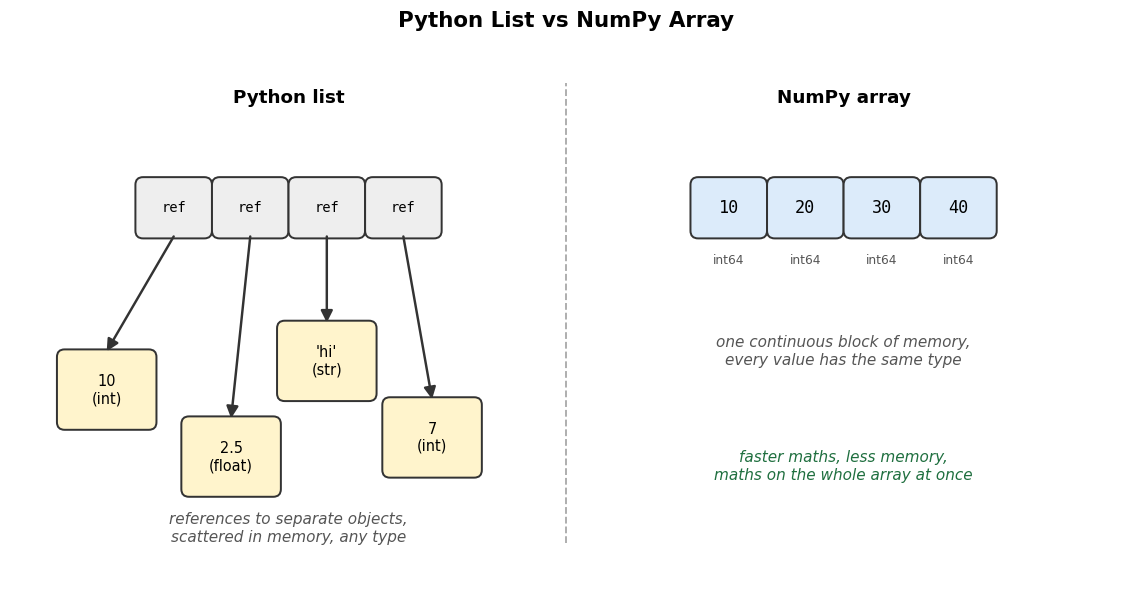

In [ ]:
# Example 1: The same operators do different things
import numpy as np

prices_list = [100, 200, 300]
prices_array = np.array([100, 200, 300])

print(prices_list * 2)                         # list: repeats the list
print(prices_array * 2)                        # array: doubles every number
print(prices_list + [10, 20, 30])              # list: joins the two lists
print(prices_array + np.array([10, 20, 30]))   # array: adds element by element
# Expected output:
# [100, 200, 300, 100, 200, 300]
# [200 400 600]
# [100, 200, 300, 10, 20, 30]
# [110 220 330]

In [ ]:
# Example 2: Converting prices from dollars to rupees (at 83 rupees per dollar)
dollars = [10, 25, 40]
rupees = []
for d in dollars:                  # a list needs a loop
    rupees.append(d * 83)
print(rupees)

dollars_arr = np.array([10, 25, 40])
print(dollars_arr * 83)            # an array needs one line
# Expected output:
# [830, 2075, 3320]
# [ 830 2075 3320]

In [ ]:
# Example 3: Speed test - squaring one million numbers
import time

numbers_list = list(range(1_000_000))     # the _ in 1_000_000 just makes it easier to read
numbers_array = np.arange(1_000_000)

start = time.perf_counter()
squares_list = []
for n in numbers_list:
    squares_list.append(n * n)
list_time = time.perf_counter() - start

start = time.perf_counter()
squares_array = numbers_array * numbers_array
array_time = time.perf_counter() - start

print(f'List loop: {list_time:.4f} seconds')
print(f'NumPy    : {array_time:.4f} seconds')
print(f'NumPy was about {list_time / array_time:.0f} times faster')
# Expected output (your numbers will be different):
# List loop: 0.0850 seconds
# NumPy    : 0.0020 seconds
# NumPy was about 40 times faster

In [ ]:
# Example 4: Memory - 1000 numbers in a list vs an array
import sys

numbers_list = list(range(1000))
numbers_array = np.arange(1000)

list_bytes = sys.getsizeof(numbers_list)       # the list itself (only references)
for n in numbers_list:
    list_bytes += sys.getsizeof(n)             # plus every separate int object
print('List :', list_bytes, 'bytes')
print('Array:', numbers_array.nbytes, 'bytes')
# Expected output (the list number depends on your Python version):
# List : about 36000 bytes
# Array: 8000 bytes

In [ ]:
# Example 5: An array holds ONE type - NumPy converts mixed values
mixed = np.array([1, 2.5, 3])
print(mixed)                         # every element became a decimal (float)
print(np.array([1, 'two', 3]))       # every element became text
# Expected output:
# [1.  2.5 3. ]
# ['1' 'two' '3']

---
# Part 2: Introduction to NumPy (Numerical Python)

**NumPy** (Numerical Python) is the main Python library for fast work with numbers. Its core is the **ndarray** (n-dimensional array): a grid of values, all of the same type.

- It is written largely in C, so it is very fast.
- It is the foundation of most data libraries: **pandas**, **Matplotlib**, **scikit-learn** and **TensorFlow** all use NumPy arrays.
- It is pre-installed in Colab and Anaconda. Elsewhere, install it with `pip install numpy`.
- It is always imported with the short name `np`:
```python
import numpy as np
```

### Dimensions

| Dimensions (`ndim`) | Name | Looks like | Real-life example |
|---|---|---|---|
| 0 | scalar | `42` | one temperature reading |
| 1 | vector | `[1, 2, 3]` | the marks of one student |
| 2 | matrix | rows and columns | the marks of a class: students x subjects |
| 3 | 3-D array | a stack of tables | a colour image: height x width x 3 colours |

Each direction of an array is called an **axis**. In a 2-D array, **axis 0** runs down the rows and **axis 1** runs across the columns.

**Diagram: Dimensions and axes**

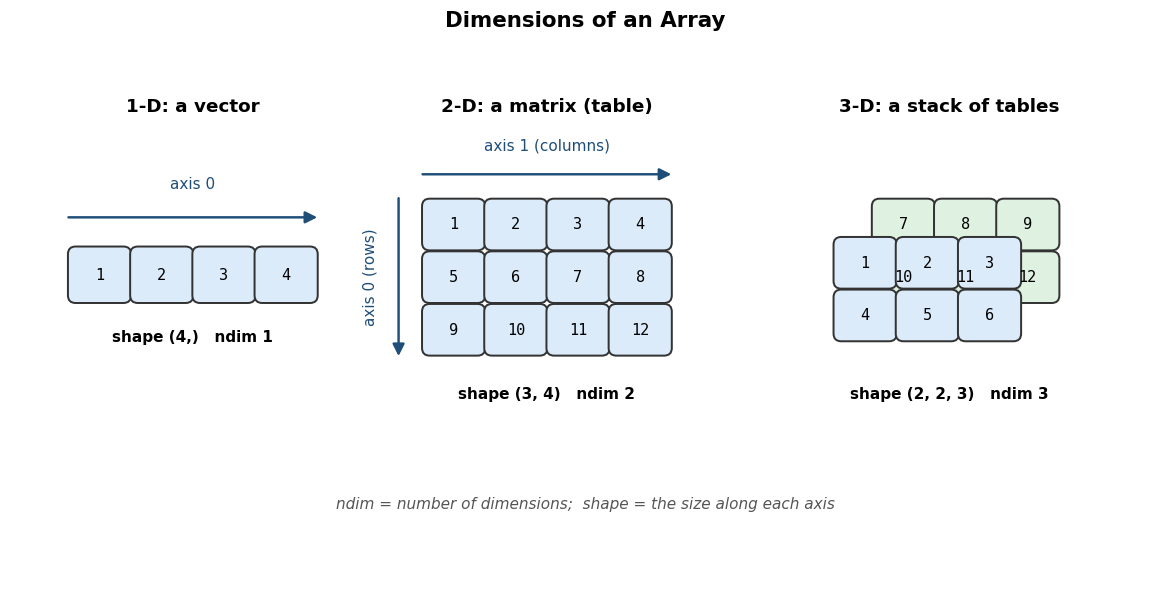

In [ ]:
# Example 1: Checking NumPy
import numpy as np
print(np.__version__)
print(type(np.array([1, 2, 3])))
# Expected output:
# a version number such as 2.0.2
# <class 'numpy.ndarray'>

In [ ]:
# Example 2: Arrays with 0, 1, 2 and 3 dimensions
scalar = np.array(42)
vector = np.array([1, 2, 3])
matrix = np.array([[1, 2, 3],
                   [4, 5, 6]])
cube = np.array([[[1, 2], [3, 4]],
                 [[5, 6], [7, 8]]])
print(scalar.ndim, vector.ndim, matrix.ndim, cube.ndim)
print(matrix)
print(matrix.shape)            # (rows, columns)
# Expected output:
# 0 1 2 3
# [[1 2 3]
#  [4 5 6]]
# (2, 3)

---
# Part 3: Creating Arrays

| Function | Creates | Example |
|---|---|---|
| `np.array(list)` | an array from a list (or a list of lists) | `np.array([1, 2, 3])` |
| `np.zeros(shape)` | all zeros | `np.zeros((2, 3))` |
| `np.ones(shape)` | all ones | `np.ones(5)` |
| `np.full(shape, value)` | every element set to one value | `np.full((2, 2), 7)` |
| `np.eye(n)` | an identity matrix (1s on the diagonal) | `np.eye(3)` |
| `np.arange(start, stop, step)` | evenly stepped numbers (Part 4) | `np.arange(0, 10, 2)` |
| `np.linspace(start, stop, num)` | `num` evenly spaced numbers, stop included | `np.linspace(0, 1, 5)` |
| `rng.integers(low, high, size)` | random whole numbers | `rng.integers(1, 7, size=10)` |

The **shape** is written as a tuple, `(rows, columns)`. A single number means a 1-D array.

The optional **`dtype`** argument chooses the element type: `int`, `float`, `bool` or `str`.

In [ ]:
# Example 1: From lists (1-D) and lists of lists (2-D)
marks = np.array([78, 92, 65, 88])
table = np.array([[78, 92, 65],
                  [88, 70, 95]])
print(marks)
print(table)
# Expected output:
# [78 92 65 88]
# [[78 92 65]
#  [88 70 95]]

In [ ]:
# Example 2: Choosing the element type with dtype
a = np.array([1, 2, 3], dtype=float)
b = np.array([1.7, 2.2, 3.9], dtype=int)    # the decimals are cut off, not rounded
c = np.array([0, 1, 2], dtype=bool)          # 0 is False, anything else is True
print(a)
print(b)
print(c)
# Expected output:
# [1. 2. 3.]
# [1 2 3]
# [False  True  True]

In [ ]:
# Example 3: zeros, ones and full
print(np.zeros(4))
print(np.ones((2, 3), dtype=int))
print(np.full((2, 2), 7))
# Expected output:
# [0. 0. 0. 0.]
# [[1 1 1]
#  [1 1 1]]
# [[7 7]
#  [7 7]]

In [ ]:
# Example 4: The identity matrix
print(np.eye(3, dtype=int))
# Expected output:
# [[1 0 0]
#  [0 1 0]
#  [0 0 1]]

In [ ]:
# Example 5: linspace - a chosen NUMBER of evenly spaced values (the stop is included)
print(np.linspace(0, 1, 5))
print(np.linspace(0, 100, 3))
# Expected output:
# [0.   0.25 0.5  0.75 1.  ]
# [  0.  50. 100.]

In [ ]:
# Example 6: Random numbers (useful for practice data and simulations)
rng = np.random.default_rng(seed=42)       # a random number generator; the seed makes results repeatable
dice = rng.integers(1, 7, size=10)         # 10 dice rolls: 1 to 6 (7 is not included)
scores = rng.integers(0, 101, size=(3, 4)) # a 3 x 4 table of random marks
print(dice)
print(scores)
print(rng.random(3).round(2))              # 3 random decimals between 0 and 1
# Expected output: random numbers - but the SAME ones every time you run, because of the seed.
# (Older code uses np.random.seed(42) and np.random.randint(1, 7, 10); you may see it online.)

---
# Part 4: np.arange() - Ranges of Numbers

`np.arange()` works like Python's `range()`, but it returns a **NumPy array**, and it also allows **decimal** steps.

**Syntax:**
```python
np.arange(stop)                 # 0, 1, 2, ... up to stop-1
np.arange(start, stop)          # start ... up to stop-1
np.arange(start, stop, step)    # start, start+step, ...  (stop is NOT included)
```

| Call | Result |
|---|---|
| `np.arange(5)` | `[0 1 2 3 4]` |
| `np.arange(1, 6)` | `[1 2 3 4 5]` |
| `np.arange(0, 20, 5)` | `[ 0  5 10 15]` |
| `np.arange(5, 0, -1)` | `[5 4 3 2 1]` |
| `np.arange(0, 1, 0.25)` | `[0.   0.25 0.5  0.75]` |

**arange or linspace?** Use `arange` when you know the **step**. Use `linspace` when you know **how many** values you want, especially with decimals, because decimal steps in `arange` can produce one extra value (Example 4).

**Diagram: np.arange() vs np.linspace()**

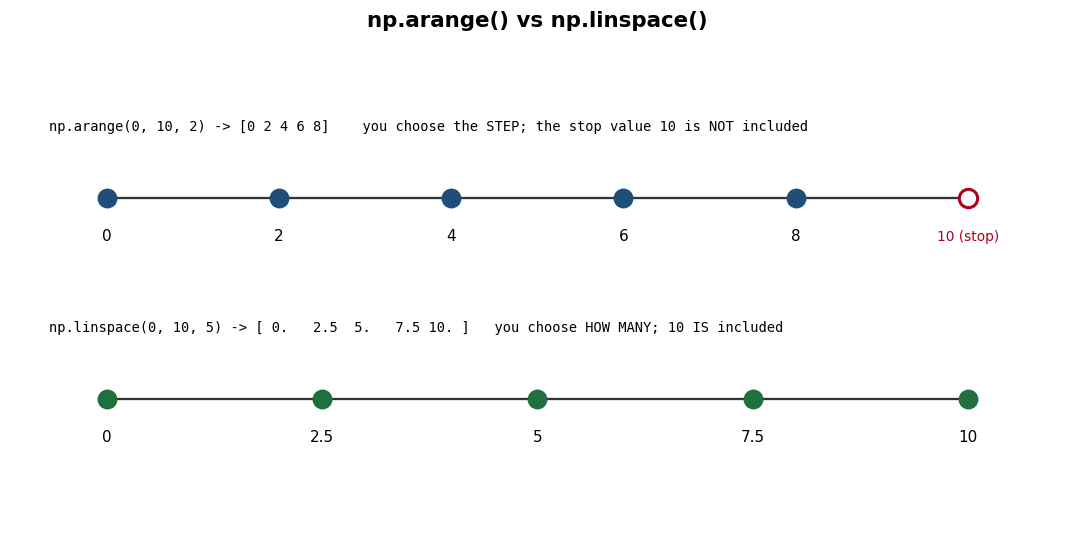

In [ ]:
# Example 1: Whole-number ranges
print(np.arange(10))
print(np.arange(1, 11))
print(np.arange(0, 50, 5))
print(np.arange(10, 0, -2))
# Expected output:
# [0 1 2 3 4 5 6 7 8 9]
# [ 1  2  3  4  5  6  7  8  9 10]
# [ 0  5 10 15 20 25 30 35 40 45]
# [10  8  6  4  2]

In [ ]:
# Example 2: Decimal steps (range() cannot do this)
print(np.arange(0, 1, 0.25))
print(np.arange(1.5, 3.0, 0.5))
# Expected output:
# [0.   0.25 0.5  0.75]
# [1.5 2.  2.5]

In [ ]:
# Example 3: arange vs range
r = range(5)
a = np.arange(5)
print(list(r), a)
print(a * 10)           # an array supports maths directly
# print(r * 10)         # TypeError: unsupported operand type(s) for *: 'range' and 'int'
# Expected output:
# [0, 1, 2, 3, 4] [0 1 2 3 4]
# [ 0 10 20 30 40]

In [ ]:
# Example 4: The decimal-step trap, and how linspace avoids it
print(np.arange(1, 1.3, 0.1))     # tiny rounding errors in 0.1 produce an EXTRA value, 1.3
print(np.linspace(1, 1.2, 3))     # linspace: you choose exactly how many values
# Expected output:
# [1.  1.1 1.2 1.3]
# [1.  1.1 1.2]

In [ ]:
# Example 5: Quick real uses of arange
print(np.arange(2, 21, 2))          # even numbers up to 20
print(7 * np.arange(1, 11))         # the 7 times table
print(np.arange(2020, 2027))        # a range of years
# Expected output:
# [ 2  4  6  8 10 12 14 16 18 20]
# [ 7 14 21 28 35 42 49 56 63 70]
# [2020 2021 2022 2023 2024 2025 2026]

---
# Part 5: Array Attributes

Attributes describe an array. They are written **without brackets**, because they are not methods.

| Attribute | Meaning | For a 3 x 4 table of whole numbers |
|---|---|---|
| `arr.ndim` | number of dimensions | `2` |
| `arr.shape` | size along each dimension (rows, columns) | `(3, 4)` |
| `arr.size` | total number of elements | `12` |
| `arr.dtype` | type of the elements | `int64` |
| `arr.itemsize` | bytes used by one element | `8` |
| `arr.nbytes` | bytes used by all elements | `96` |
| `arr.T` | the transposed array (rows and columns swapped) | shape `(4, 3)` |

To change the element type, use the method `arr.astype(new_type)`. It returns a **new** array.

(On some Windows computers with an older NumPy, the default integer type is `int32`, which uses 4 bytes.)

In [ ]:
# Example 1: All the main attributes of a 2-D array
marks = np.array([[78, 92, 65, 88],
                  [55, 70, 81, 60],
                  [90, 85, 77, 95]])     # 3 students x 4 subjects
print('ndim    :', marks.ndim)
print('shape   :', marks.shape)
print('size    :', marks.size)
print('dtype   :', marks.dtype)
print('itemsize:', marks.itemsize, 'bytes')
print('nbytes  :', marks.nbytes, 'bytes')
# Expected output:
# ndim    : 2
# shape   : (3, 4)
# size    : 12
# dtype   : int64
# itemsize: 8 bytes
# nbytes  : 96 bytes

In [ ]:
# Example 2: Shapes of 1-D and 3-D arrays
a = np.arange(6)
image = np.zeros((4, 5, 3))       # a tiny colour image: 4 rows x 5 columns x 3 colours
print(a.shape, a.ndim)
print(image.shape, image.ndim, image.size)
# Expected output:
# (6,) 1
# (4, 5, 3) 3 60

In [ ]:
# Example 3: Using the shape in your code
rows, cols = marks.shape           # unpack the tuple
print(f'{rows} students, {cols} subjects')
print(len(marks))                  # len() gives the size of the FIRST dimension (the rows)
# Expected output:
# 3 students, 4 subjects
# 3

In [ ]:
# Example 4: Changing the type with astype()
prices = np.array([99.5, 149.9, 20.0])
print(prices.dtype)
whole = prices.astype(int)          # a NEW array; the decimals are cut off
print(whole, whole.dtype)
text = np.array(['10', '20', '30'])
numbers = text.astype(int)          # text to numbers, e.g. after reading a file
print(numbers.sum())
# Expected output:
# float64
# [ 99 149  20] int64
# 60

In [ ]:
# Example 5: Trap - an integer array cannot hold decimals
scores = np.array([10, 20, 30])
scores[0] = 9.7          # silently cut down to 9!
print(scores)
scores = scores.astype(float)
scores[0] = 9.7
print(scores)
# Expected output:
# [ 9 20 30]
# [ 9.7 20.  30. ]

---
# Part 6: Reshaping Arrays

| Method | What it does |
|---|---|
| `arr.reshape(rows, cols)` | the same values arranged in a new shape. The total size must stay the same: 12 values can be 3 x 4, 2 x 6 or 4 x 3 |
| `arr.reshape(rows, -1)` | `-1` means: work this size out for me |
| `arr.flatten()` | any shape back to 1-D (a copy) |
| `arr.T` | transpose: rows become columns |

The values are filled in **row by row**.

**Diagram: Reshaping an array**

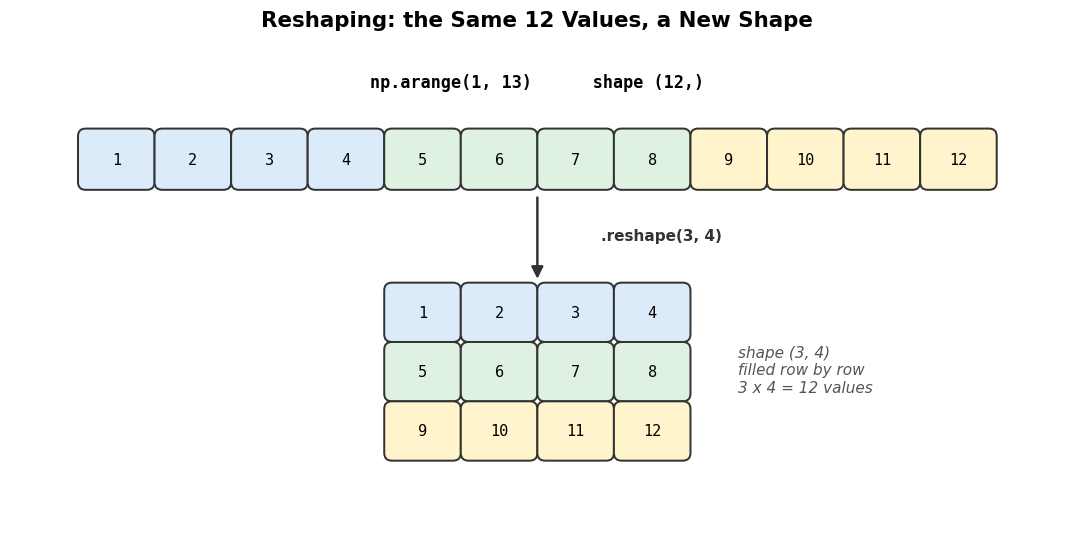

In [ ]:
# Example 1: 12 values as 3 x 4 and as 4 x 3
nums = np.arange(1, 13)
print(nums)
grid = nums.reshape(3, 4)
print(grid)
print(nums.reshape(4, 3))
# Expected output:
# [ 1  2  3  4  5  6  7  8  9 10 11 12]
# [[ 1  2  3  4]
#  [ 5  6  7  8]
#  [ 9 10 11 12]]
# [[ 1  2  3]
#  [ 4  5  6]
#  [ 7  8  9]
#  [10 11 12]]

In [ ]:
# Example 2: Let NumPy work out one size with -1
print(nums.reshape(2, -1))          # 2 rows, so NumPy works out 6 columns
print(nums.reshape(-1, 2).shape)
# nums.reshape(5, 3)                # ValueError: cannot reshape array of size 12 into shape (5,3)
# Expected output:
# [[ 1  2  3  4  5  6]
#  [ 7  8  9 10 11 12]]
# (6, 2)

In [ ]:
# Example 3: flatten() and transpose (.T)
print(grid.flatten())
print(grid.T)                       # rows become columns
print(grid.T.shape)
# Expected output:
# [ 1  2  3  4  5  6  7  8  9 10 11 12]
# [[ 1  5  9]
#  [ 2  6 10]
#  [ 3  7 11]
#  [ 4  8 12]]
# (4, 3)

In [ ]:
# Example 4: A real use - 14 days of step counts as 2 weeks x 7 days
daily_steps = np.array([4000, 6500, 8000, 7200, 5000, 12000, 9000,
                        3000, 7000, 7500, 8200, 6000, 11000, 10000])
weeks = daily_steps.reshape(2, 7)
print(weeks)
print('Steps per week:', weeks.sum(axis=1))     # sum(axis=1) is explained in Part 11
# Expected output:
# [[ 4000  6500  8000  7200  5000 12000  9000]
#  [ 3000  7000  7500  8200  6000 11000 10000]]
# Steps per week: [51700 52700]

---
# Part 7: Indexing and Slicing

**1-D arrays** work just like lists: `a[0]`, `a[-1]`, `a[1:4]`, `a[::2]`, `a[::-1]`.

**2-D arrays** use **one pair of brackets** with `row, column`:

| Code | Selects |
|---|---|
| `arr[1, 2]` | one element: row 1, column 2 |
| `arr[1]` | the whole of row 1 |
| `arr[:, 2]` | the whole of column 2 (`:` means all rows) |
| `arr[0:2, 1:3]` | rows 0-1 and columns 1-2 (a sub-table) |
| `arr[[0, 2]]` | rows 0 and 2 (a list of positions, called *fancy indexing*) |

**An important difference from lists:** slicing a NumPy array gives a **view**, not a copy. Changing the slice changes the original array. Use `.copy()` when you need an independent copy (Example 6).

**Diagram: Indexing a 2-D array**

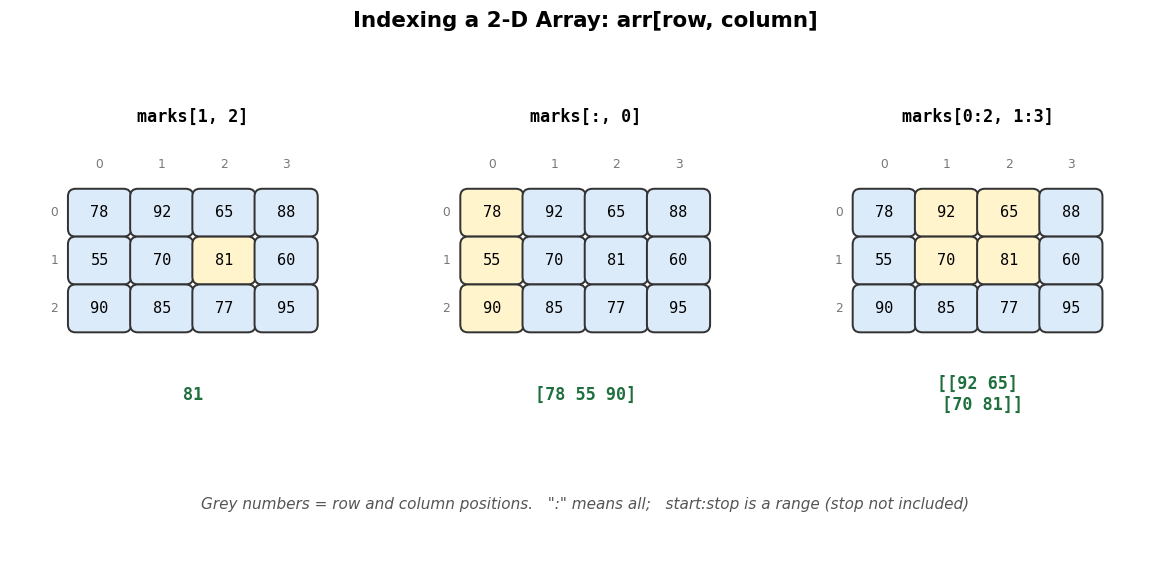

In [ ]:
# Example 1: 1-D indexing and slicing (just like lists)
temps = np.array([28, 31, 33, 30, 27, 25, 29])     # a week of temperatures
print(temps[0], temps[-1])
print(temps[1:4])
print(temps[::2])
print(temps[::-1])
# Expected output:
# 28 29
# [31 33 30]
# [28 33 27 29]
# [29 25 27 30 33 31 28]

In [ ]:
# Example 2: One element, one row, one column
marks = np.array([[78, 92, 65, 88],
                  [55, 70, 81, 60],
                  [90, 85, 77, 95]])
print(marks[0, 1])        # row 0, column 1
print(marks[2, -1])       # row 2, last column
print(marks[1])           # the whole of row 1
print(marks[:, 0])        # the whole of column 0
# Expected output:
# 92
# 95
# [55 70 81 60]
# [78 55 90]

In [ ]:
# Example 3: Sub-tables with slices
print(marks[0:2, 1:3])    # rows 0-1, columns 1-2
print(marks[:, -2:])      # every row, the last two columns
# Expected output:
# [[92 65]
#  [70 81]]
# [[65 88]
#  [81 60]
#  [77 95]]

In [ ]:
# Example 4: Fancy indexing - choose rows or columns with a list of positions
print(marks[[0, 2]])          # rows 0 and 2
print(marks[:, [0, 3]])       # columns 0 and 3
# Expected output:
# [[78 92 65 88]
#  [90 85 77 95]]
# [[78 88]
#  [55 60]
#  [90 95]]

In [ ]:
# Example 5: Changing values through indexing
marks[1, 0] = 58                  # correct one mark
marks[:, 2] = marks[:, 2] + 5     # 5 bonus marks for everyone in subject 2
print(marks)
# Expected output:
# [[78 92 70 88]
#  [58 70 86 60]
#  [90 85 82 95]]

In [ ]:
# Example 6: Trap - a slice is a VIEW of the original array
original = np.array([10, 20, 30, 40, 50])
part = original[1:4]          # a view: it shares its data with the original
part[0] = 999
print(original)               # the original changed too!

original = np.array([10, 20, 30, 40, 50])
safe = original[1:4].copy()   # a real, independent copy
safe[0] = 999
print(original)
print(safe)
# Expected output:
# [ 10 999  30  40  50]
# [10 20 30 40 50]
# [999  30  40]

---
# Part 8: Element-wise Arithmetic

Arithmetic operators work on arrays **element by element**: the first element with the first, the second with the second, and so on. No loops are needed.

With `a = [10, 20, 30, 40]` and `b = [1, 2, 3, 4]`:

| Operator | Meaning | Example | Result |
|---|---|---|---|
| `+` | addition | `a + b` | `[11 22 33 44]` |
| `-` | subtraction | `a - b` | `[ 9 18 27 36]` |
| `*` | multiplication | `a * b` | `[ 10  40  90 160]` |
| `/` | division (always gives decimals) | `a / b` | `[10. 10. 10. 10.]` |
| `//` | floor division | `a // 3` | `[ 3  6 10 13]` |
| `%` | remainder | `a % 3` | `[1 2 0 1]` |
| `**` | power | `b ** 2` | `[ 1  4  9 16]` |

- The arrays must have the **same shape**, or shapes that can be **broadcast** (Part 9). A single number (a **scalar**) always works: `a * 2`.
- Comparison operators (`>`, `<`, `==`, `!=`, `>=`, `<=`) also work element by element and give an array of `True`/`False`.
- `*` multiplies element by element. For **matrix multiplication** (rows times columns), use `@` (Example 7).

**Diagram: Element-wise arithmetic**

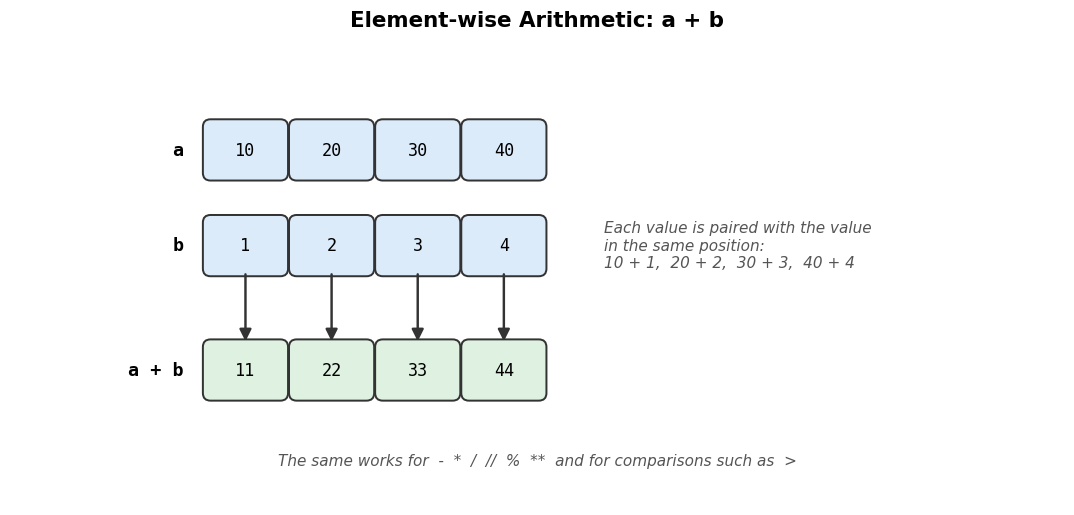

In [ ]:
# Example 1: Two arrays of the same shape
a = np.array([10, 20, 30, 40])
b = np.array([1, 2, 3, 4])
print(a + b)
print(a - b)
print(a * b)
print(a / b)
print(a // 3)
print(a % 3)
print(b ** 2)
# Expected output:
# [11 22 33 44]
# [ 9 18 27 36]
# [ 10  40  90 160]
# [10. 10. 10. 10.]
# [ 3  6 10 13]
# [1 2 0 1]
# [ 1  4  9 16]

In [ ]:
# Example 2: An array and a single number (scalar)
prices = np.array([250, 400, 1200])
print(prices + 50)            # add a delivery charge to each price
print(prices * 2)
print(prices / 100)
# Expected output:
# [ 300  450 1250]
# [ 500  800 2400]
# [ 2.5  4.  12. ]

In [ ]:
# Example 3: A shopping bill without a loop
quantity = np.array([2, 3, 1])           # rice, milk, bread
unit_price = np.array([60, 45, 40])
amount = quantity * unit_price
print(amount)
print('Total bill:', amount.sum())
# Expected output:
# [120 135  40]
# Total bill: 295

In [ ]:
# Example 4: A formula applied to every element
celsius = np.array([0, 25, 37, 100])
fahrenheit = celsius * 9 / 5 + 32
print(fahrenheit)
# Expected output:
# [ 32.   77.   98.6 212. ]

In [ ]:
# Example 5: Comparisons give arrays of True / False
marks = np.array([35, 72, 48, 90, 39])
print(marks >= 40)
print(marks == 90)
# Expected output:
# [False  True  True  True False]
# [False False False  True False]

In [ ]:
# Example 6: The shapes must match
x = np.array([1, 2, 3])
y = np.array([10, 20])
# x + y      # ValueError: operands could not be broadcast together with shapes (3,) (2,)
print('The arrays must have matching shapes (or follow the broadcasting rules in Part 9)')
# Expected output: The arrays must have matching shapes (or follow the broadcasting rules in Part 9)

In [ ]:
# Example 7: Element-wise * vs matrix multiplication @
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])
print(A * B)      # element by element: 1*5, 2*6, 3*7, 4*8
print(A @ B)      # matrix multiplication: rows of A times columns of B
# Expected output:
# [[ 5 12]
#  [21 32]]
# [[19 22]
#  [43 50]]

---
# Part 9: Broadcasting

**Broadcasting** lets NumPy do arithmetic on arrays of **different shapes**. The smaller array is (virtually) repeated to match the bigger one, without making copies.

**The rule:** compare the shapes **from the right**. Two sizes are compatible if they are **equal**, or if **one of them is 1** (or missing).

| Shapes | Works? | What happens |
|---|---|---|
| `(2, 3)` and a scalar | yes | the number is used for every element |
| `(2, 3)` and `(3,)` | yes | the 1-D array is applied to **every row** |
| `(2, 3)` and `(2, 1)` | yes | the column is applied to **every column** |
| `(2, 3)` and `(2,)` | **no** | the last sizes, 3 and 2, do not match: `ValueError` |

**Diagram: Broadcasting**

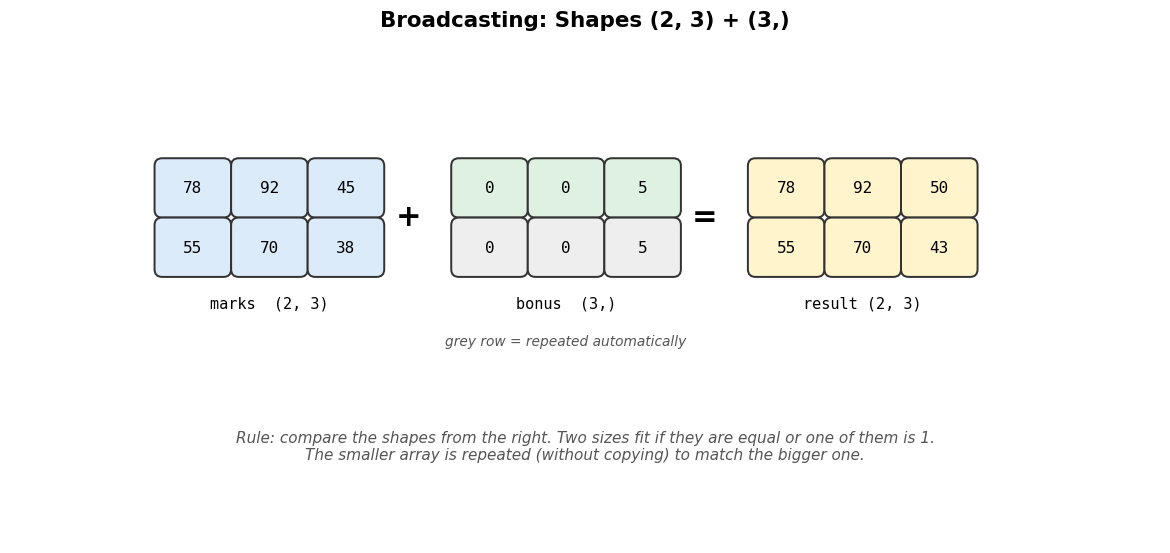

In [ ]:
# Example 1: A scalar is broadcast to every element
marks = np.array([[78, 92, 45],
                  [55, 70, 38]])      # 2 students x 3 subjects (the third is out of 50)
print(marks + 5)
# Expected output:
# [[83 97 50]
#  [60 75 43]]

In [ ]:
# Example 2: A row (shape (3,)) is applied to every row of a (2, 3) array
max_marks = np.array([100, 100, 50])
percent = marks * 100 / max_marks
print(percent)
# Expected output:
# [[78. 92. 90.]
#  [55. 70. 76.]]

In [ ]:
# Example 3: A column (shape (2, 1)) is applied to every column
bonus = np.array([[5],
                  [10]])          # one bonus per student
print(marks + bonus)
# Expected output:
# [[83 97 50]
#  [65 80 48]]

In [ ]:
# Example 4: A row and a column together make a whole table
n = np.arange(1, 6)
table = n.reshape(5, 1) * n       # (5, 1) times (5,) gives (5, 5)
print(table)
# Expected output:
# [[ 1  2  3  4  5]
#  [ 2  4  6  8 10]
#  [ 3  6  9 12 15]
#  [ 4  8 12 16 20]
#  [ 5 10 15 20 25]]

In [ ]:
# Example 5: Shapes that cannot be broadcast
a = np.ones((2, 3))
b = np.array([1, 2])
# a + b     # ValueError: operands could not be broadcast together with shapes (2,3) (2,)
print('(2, 3) and (2,): the last sizes are 3 and 2, which do not match')
# Expected output: (2, 3) and (2,): the last sizes are 3 and 2, which do not match

---
# Part 10: Mathematical Functions

NumPy's maths functions work on every element at once. They are called **universal functions** (ufuncs).

| Function | Does | Example | Result |
|---|---|---|---|
| `np.sqrt(a)` | square root | `np.sqrt([4, 9])` | `[2. 3.]` |
| `np.square(a)` | square | `np.square([2, 3])` | `[4 9]` |
| `np.abs(a)` | absolute value | `np.abs([-2, 3])` | `[2 3]` |
| `np.round(a, n)` | round to n decimal places | `np.round([1.256], 2)` | `[1.26]` |
| `np.floor(a)`, `np.ceil(a)` | round down, round up | `np.ceil([1.2])` | `[2.]` |
| `np.exp(a)`, `np.log(a)` | e to the power x, natural logarithm | | |
| `np.sin(a)`, `np.cos(a)` | trigonometry (angles in radians) | | |
| `np.pi` | the constant pi | | `3.14159...` |

In [ ]:
# Example 1: Square roots and squares
nums = np.array([1, 4, 9, 16, 25])
print(np.sqrt(nums))
print(np.square(nums[:3]))
# Expected output:
# [1. 2. 3. 4. 5.]
# [ 1 16 81]

In [ ]:
# Example 2: abs, round, floor and ceil
changes = np.array([-2.76, 3.42, -0.58, 7.31])
print(np.abs(changes))
print(np.round(changes, 1))
prices = np.array([19.2, 45.7, 99.5])
print(np.floor(prices))       # round down
print(np.ceil(prices))        # round up
# Expected output:
# [2.76 3.42 0.58 7.31]
# [-2.8  3.4 -0.6  7.3]
# [19. 45. 99.]
# [ 20.  46. 100.]

In [ ]:
# Example 3: pi and trigonometry
print(np.round(np.pi, 4))
angles = np.array([0, 30, 90])                         # degrees
print(np.round(np.sin(np.radians(angles)), 2))         # np.radians() converts degrees to radians
# Expected output:
# 3.1416
# [0.  0.5 1. ]

In [ ]:
# Example 4: A real use - compound interest on 10,000 at 8% a year, for 0 to 5 years
years = np.arange(0, 6)
amount = 10000 * (1 + 0.08) ** years
print(np.round(amount, 2))
# Expected output:
# [10000.   10800.   11664.   12597.12 13604.89 14693.28]

---
# Part 11: Aggregation and Statistics

Aggregation functions reduce many values to one value (or to one value per row or column).

| Function | Gives |
|---|---|
| `arr.sum()` | total |
| `arr.mean()` | average |
| `np.median(arr)` | middle value |
| `arr.min()`, `arr.max()` | smallest, largest |
| `arr.argmin()`, `arr.argmax()` | the **position** of the smallest / largest |
| `arr.std()`, `arr.var()` | standard deviation, variance (how spread out the values are) |
| `arr.cumsum()` | running total |

### The axis argument (2-D arrays)
- **No axis:** one result for the whole array
- **`axis=0`:** goes **down the rows**, giving one result **per column**
- **`axis=1`:** goes **across the columns**, giving one result **per row**

Tip: for a table of students (rows) x subjects (columns), `axis=0` gives **subject** results and `axis=1` gives **student** results.

**Diagram: axis=0 vs axis=1**

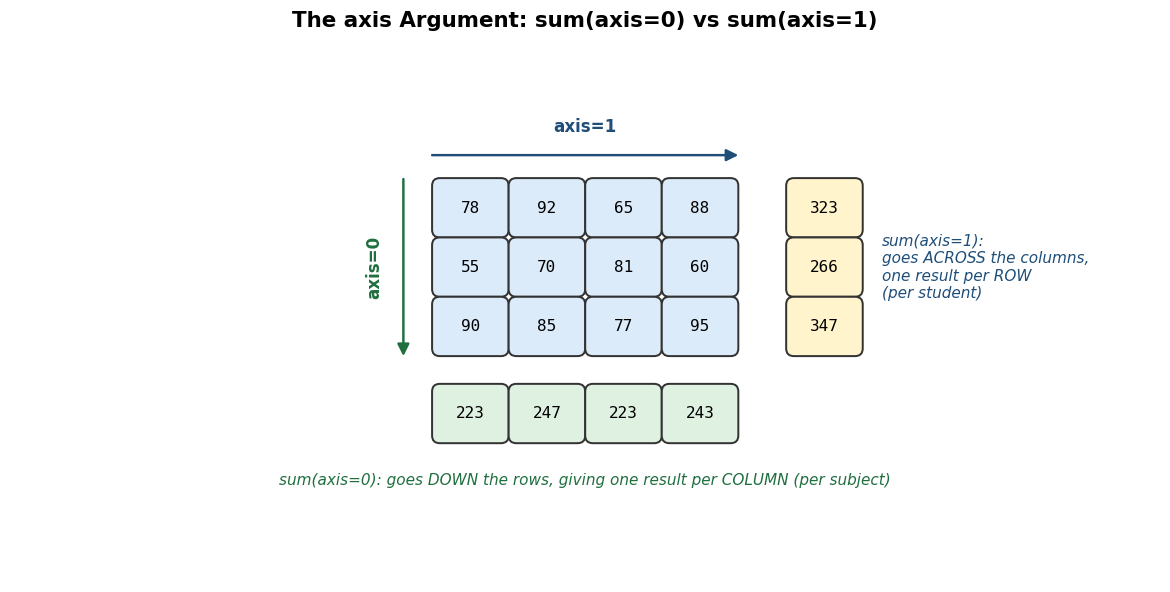

In [ ]:
# Example 1: Statistics of one week's sales
sales = np.array([120, 340, 560, 210, 450, 380, 320])
print('Total  :', sales.sum())
print('Average:', sales.mean())
print('Median :', np.median(sales))
print('Lowest :', sales.min(), 'on day', sales.argmin() + 1)
print('Highest:', sales.max(), 'on day', sales.argmax() + 1)
print('Std dev:', round(sales.std(), 2))
# Expected output:
# Total  : 2380
# Average: 340.0
# Median : 340.0
# Lowest : 120 on day 1
# Highest: 560 on day 3
# Std dev: 135.12

In [ ]:
# Example 2: axis=0 (per column) and axis=1 (per row)
marks = np.array([[78, 92, 65, 88],
                  [55, 70, 81, 60],
                  [90, 85, 77, 95]])     # rows = students, columns = subjects
print('Total of everything  :', marks.sum())
print('Per subject (axis=0) :', marks.sum(axis=0))
print('Per student (axis=1) :', marks.sum(axis=1))
print('Subject averages     :', np.round(marks.mean(axis=0), 1))
print('Best mark per student:', marks.max(axis=1))
# Expected output:
# Total of everything  : 936
# Per subject (axis=0) : [223 247 223 243]
# Per student (axis=1) : [323 266 347]
# Subject averages     : [74.3 82.3 74.3 81. ]
# Best mark per student: [92 81 95]

In [ ]:
# Example 3: argmax with an axis - who topped each subject?
students = np.array(['Asha', 'Ravi', 'Meena'])
subjects = np.array(['Maths', 'Science', 'English', 'Hindi'])
best = marks.argmax(axis=0)          # the row number of the highest mark in each column
print(best)
for subject, row in zip(subjects, best):
    print(f'{subject}: {students[row]}')
# Expected output:
# [2 0 1 2]
# Maths: Meena
# Science: Asha
# English: Ravi
# Hindi: Meena

In [ ]:
# Example 4: Running totals and percentages of a total
monthly_savings = np.array([2000, 1500, 3000, 2500])
print(monthly_savings.cumsum())               # savings so far, month by month
expenses = np.array([1200, 800, 500, 2500])   # food, travel, bills, rent
print(np.round(expenses / expenses.sum() * 100, 1))
# Expected output:
# [2000 3500 6500 9000]
# [24. 16. 10. 50.]

---
# Part 12: Boolean Indexing and Filtering

A condition on an array gives a **boolean array** (a **mask**) of `True`/`False`. Putting that mask inside `[ ]` keeps only the elements where it is `True`:
```python
marks[marks >= 40]      # only the passing marks
```

- Combine conditions with `&` (**and**), `|` (**or**) and `~` (**not**).
- **Always put each condition in brackets:** `(marks >= 40) & (marks < 70)`.
- Do **not** use the words `and`, `or`, `not` with arrays: they give a `ValueError`.
- `mask.sum()` counts the `True` values; `mask.mean()` gives the fraction that are `True`.
- `np.any(mask)` asks: is at least one `True`? `np.all(mask)` asks: are they all `True`?
- `np.where(condition, value_if_true, value_if_false)` is an if-else for every element.
- `np.select(conditions, choices, default)` is an if-elif-else for every element.
- `arr[mask] = value` changes only the selected elements.

**Diagram: Boolean indexing with a mask**

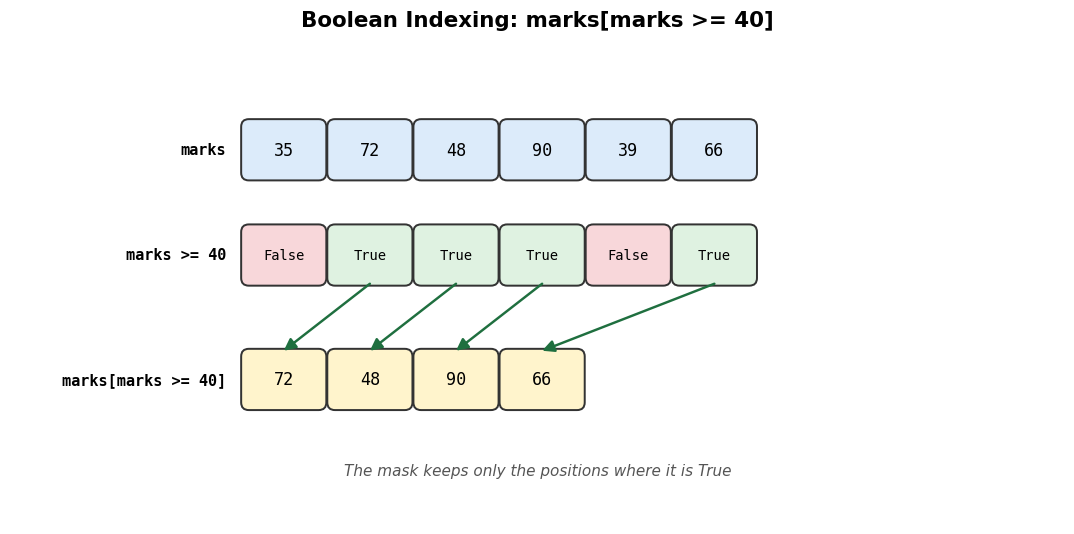

In [ ]:
# Example 1: A mask and filtering
marks = np.array([35, 72, 48, 90, 39, 66])
mask = marks >= 40
print(mask)
print(marks[mask])
print(marks[marks < 40])        # usually written in one step
# Expected output:
# [False  True  True  True False  True]
# [72 48 90 66]
# [35 39]

In [ ]:
# Example 2: Combining conditions with & | ~
print(marks[(marks >= 40) & (marks < 70)])     # between 40 and 69
print(marks[(marks < 40) | (marks > 85)])      # failed OR excellent
print(marks[~(marks >= 40)])                    # NOT passed
# marks[marks >= 40 and marks < 70]   # ValueError: The truth value of an array ... is ambiguous
# Expected output:
# [48 66]
# [35 90 39]
# [35 39]

In [ ]:
# Example 3: Counting with masks
print('Passed:', (marks >= 40).sum())
print('Pass rate:', round((marks >= 40).mean() * 100, 1), '%')
print('Anyone above 85?', np.any(marks > 85))
print('Everyone passed?', np.all(marks >= 40))
# Expected output:
# Passed: 4
# Pass rate: 66.7 %
# Anyone above 85? True
# Everyone passed? False

In [ ]:
# Example 4: np.where - an if-else for every element
result = np.where(marks >= 40, 'Pass', 'Fail')
print(result)
graced = np.where(marks < 40, marks + 5, marks)    # 5 grace marks only for those below 40
print(graced)
print(np.where(marks >= 40))        # with only a condition: the positions where it is True
# Expected output:
# ['Fail' 'Pass' 'Pass' 'Pass' 'Fail' 'Pass']
# [40 72 48 90 44 66]
# (array([1, 2, 3, 5]),)

In [ ]:
# Example 5: Changing only the selected elements
readings = np.array([12, 250, 18, -5, 22, 999])     # sensor errors: below 0 or above 100
readings[(readings < 0) | (readings > 100)] = 0
print(readings)
# Expected output: [12  0 18  0 22  0]

In [ ]:
# Example 6: Filtering the rows of a 2-D array
marks2d = np.array([[78, 92, 65, 88],
                    [55, 70, 81, 60],
                    [90, 85, 77, 95]])
names = np.array(['Asha', 'Ravi', 'Meena'])
avg = marks2d.mean(axis=1)
print(avg)
print(names[avg > 75])          # names of the students with an average above 75
print(marks2d[avg > 75])        # their rows of marks
# Expected output:
# [80.75 66.5  86.75]
# ['Asha' 'Meena']
# [[78 92 65 88]
#  [90 85 77 95]]

In [ ]:
# Example 7: np.select - more than two choices (if-elif-else for a whole array)
percent = np.array([92, 78, 64, 45, 30])
conditions = [percent >= 90, percent >= 75, percent >= 60, percent >= 40]
choices = ['A+', 'A', 'B', 'C']
print(np.select(conditions, choices, default='F'))
# Expected output: ['A+' 'A' 'B' 'C' 'F']

---
# Part 13: Sorting, Unique Values and Combining Arrays

| Function | Does |
|---|---|
| `np.sort(arr)` | returns a **new** sorted array (smallest first) |
| `np.argsort(arr)` | returns the **positions** that would sort the array: great for rankings |
| `np.unique(arr)` | the distinct values, sorted; add `return_counts=True` to also count them |
| `np.concatenate([a, b])` | joins arrays end to end |
| `np.vstack([a, b])` | stacks arrays as **rows** (vertically) |
| `np.hstack([a, b])` | joins arrays **side by side** (horizontally) |

To sort from largest to smallest, reverse the result with `[::-1]`.

In [ ]:
# Example 1: Sorting
scores = np.array([72, 95, 48, 88, 61])
print(np.sort(scores))
print(np.sort(scores)[::-1])         # highest first
print(scores)                        # np.sort() does not change the original
# Expected output:
# [48 61 72 88 95]
# [95 88 72 61 48]
# [72 95 48 88 61]

In [ ]:
# Example 2: argsort - ranking students by score
names = np.array(['Asha', 'Ravi', 'Meena', 'John', 'Sara'])
order = np.argsort(scores)[::-1]      # positions from the highest score to the lowest
print(order)
print(names[order])
print(scores[order])
# Expected output:
# [1 3 0 4 2]
# ['Ravi' 'John' 'Asha' 'Sara' 'Meena']
# [95 88 72 61 48]

In [ ]:
# Example 3: unique values and counting them
votes = np.array(['Red', 'Blue', 'Red', 'Green', 'Blue', 'Red'])
colours, counts = np.unique(votes, return_counts=True)
print(colours)
print(counts)
print('Winner:', colours[counts.argmax()])
# Expected output:
# ['Blue' 'Green' 'Red']
# [2 1 3]
# Winner: Red

In [ ]:
# Example 4: Joining arrays
jan = np.array([100, 200, 300])
feb = np.array([150, 250, 350])
print(np.concatenate([jan, feb]))
table = np.vstack([jan, feb])          # stacked as rows
print(table)
totals = table.sum(axis=1).reshape(2, 1)
print(np.hstack([table, totals]))      # add a total column on the right
# Expected output:
# [100 200 300 150 250 350]
# [[100 200 300]
#  [150 250 350]]
# [[100 200 300 600]
#  [150 250 350 750]]

---
# Part 14: Saving and Loading Arrays (Text Files)

NumPy can write an array to a **text file** and read it back. This is perfect for simple data files like the ones in the File Handling lab.

| Function / option | Does |
|---|---|
| `np.savetxt(filename, arr, fmt='%d', delimiter=',', header='...')` | writes the array, one row per line. `fmt='%d'` writes whole numbers; `'%.2f'` writes two decimals |
| `np.loadtxt(filename, delimiter=',', dtype=int)` | reads it back into an array. Lines starting with `#` are skipped |
| `skiprows=1` | skips the first line (for example a header without `#`) |
| `usecols=(1, 2)` | reads only some of the columns |

A missing file raises `FileNotFoundError`, so wrap the loading in `try-except` (Exception Handling lab).

In [ ]:
# Example 1: Saving an array to a text file
marks = np.array([[78, 92, 65],
                  [55, 70, 81],
                  [90, 85, 77]])
np.savetxt('marks_numpy.txt', marks, fmt='%d', delimiter=',', header='Maths,Science,English')
with open('marks_numpy.txt', 'r', encoding='utf-8') as f:
    print(f.read(), end='')
# Expected output:
# # Maths,Science,English
# 78,92,65
# 55,70,81
# 90,85,77

In [ ]:
# Example 2: Loading it back
loaded = np.loadtxt('marks_numpy.txt', delimiter=',', dtype=int)    # the # header line is skipped
print(loaded)
print(loaded.shape)
print('Class average:', loaded.mean())
# Expected output:
# [[78 92 65]
#  [55 70 81]
#  [90 85 77]]
# (3, 3)
# Class average: 77.0

In [ ]:
# Example 3: Handling a missing file
try:
    data = np.loadtxt('missing_file.txt')
except FileNotFoundError as e:
    print('Could not load:', e)
# Expected output: Could not load: missing_file.txt not found.

---
# Part 15: Quick Recap

| Task | Code |
|---|---|
| Import | `import numpy as np` |
| From a list | `np.array([1, 2, 3])` |
| Zeros / ones / one value | `np.zeros((2, 3))`, `np.ones(5)`, `np.full((2, 2), 7)` |
| A range with a step | `np.arange(0, 10, 2)` |
| N evenly spaced values | `np.linspace(0, 1, 5)` |
| Random numbers | `rng = np.random.default_rng(42)`, then `rng.integers(1, 7, size=5)` |
| Shape, size, type | `arr.shape`, `arr.ndim`, `arr.size`, `arr.dtype` |
| Change the shape | `arr.reshape(3, 4)`, `arr.flatten()`, `arr.T` |
| An element / a row / a column | `arr[1, 2]`, `arr[1]`, `arr[:, 2]` |
| Element-wise maths | `a + b`, `a * 2`, `a ** 2` |
| Matrix multiplication | `A @ B` |
| Statistics | `arr.sum()`, `arr.mean(axis=0)`, `arr.argmax()` |
| Filter | `arr[arr > 50]` |
| If-else on every element | `np.where(condition, x, y)` |
| Sort / rank / count | `np.sort()`, `np.argsort()`, `np.unique(..., return_counts=True)` |
| Save / load | `np.savetxt()`, `np.loadtxt()` |

### Common beginner mistakes
1. **Forgetting `import numpy as np`**: `NameError: name 'np' is not defined`.
2. **Expecting list behaviour**: for an array, `* 2` doubles the values instead of repeating them.
3. **Mixing types in `np.array`**: one string turns every element into text.
4. **Shapes that do not match** in arithmetic: `ValueError: operands could not be broadcast`.
5. **Using `and` / `or`** instead of `&` / `|`, or forgetting the brackets around each condition.
6. **Changing a slice** and accidentally changing the original array: use `.copy()`.
7. **Mixing up `axis=0` and `axis=1`**: `axis=0` gives one result per column.
8. **`reshape()` with the wrong total size**: rows x columns must equal `size`.
9. **Using `*` when you need matrix multiplication**: use `@`.
10. **Decimal steps in `arange()`** giving an extra value: use `linspace()`.
11. **Putting decimals into an integer array**: they are silently cut off; use `astype(float)` first.

---
# Part 16: Practice Exercises

Solve each exercise in the empty code cell below it, using NumPy (no `for` loops unless the exercise asks for one).

### Exercise 1: Squares with arange

Create the numbers 1 to 10 with `np.arange()`. Print their squares, and the sum of the squares.

**Expected output:**
```
[  1   4   9  16  25  36  49  64  81 100]
385
```

In [ ]:
# Write your code here


### Exercise 2: Ready-made Arrays

Create a 3 x 3 array full of 5s, and a 2 x 4 array of zeros.

**Expected output:**
```
[[5 5 5]
 [5 5 5]
 [5 5 5]]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]]
```

In [ ]:
# Write your code here


### Exercise 3: linspace

Create 5 evenly spaced values from 0 to 100 (100 included).

**Expected output:**
```
[  0.  25.  50.  75. 100.]
```

In [ ]:
# Write your code here


### Exercise 4: Attributes

For `arr = np.array([[2, 4, 6], [8, 10, 12]])`, print its shape, number of dimensions, size and data type.

**Expected output:**
```
(2, 3) 2 6 int64
```

In [ ]:
# Write your code here


### Exercise 5: Reshape and Slice

Reshape the numbers 1 to 20 into 4 rows and 5 columns. Print the third row and the last column.

**Expected output:**
```
[11 12 13 14 15]
[ 5 10 15 20]
```

In [ ]:
# Write your code here


### Exercise 6: A Bill (element-wise)

Using `prices = [40, 25, 120]` and `quantities = [3, 4, 2]`, print the amount for each item and the total.

**Expected output:**
```
[120 100 240]
Total: 460
```

In [ ]:
# Write your code here


### Exercise 7: Fahrenheit to Celsius

Convert `[32, 50, 212]` degrees Fahrenheit to Celsius using `C = (F - 32) * 5 / 9`, in one line.

**Expected output:**
```
[  0.  10. 100.]
```

In [ ]:
# Write your code here


### Exercise 8: Broadcasting a Bonus

Add the bonus row `[2, 3, 5]` (one value per subject) to every student's marks:
```python
marks = np.array([[70, 80, 90], [60, 75, 85], [50, 65, 95]])
```
**Expected output:**
```
[[ 72  83  95]
 [ 62  78  90]
 [ 52  68 100]]
```

In [ ]:
# Write your code here


### Exercise 9: Weekly Temperatures

For `temps = [31, 34, 29, 36, 33, 30, 32]` (Monday is day 1), print the highest and lowest values with their day numbers, and the average rounded to 1 decimal place.

**Expected output:**
```
Max: 36 (day 4)
Min: 29 (day 3)
Average: 32.1
```

In [ ]:
# Write your code here


### Exercise 10: Filtering

From `ages = [12, 25, 17, 40, 18, 9, 65]`, print the adults (18 or older) and how many there are.

**Expected output:**
```
[25 40 18 65]
Adults: 4
```

In [ ]:
# Write your code here


### Exercise 11: np.where

Label each number from 1 to 6 as `'Even'` or `'Odd'`.

**Expected output:**
```
['Odd' 'Even' 'Odd' 'Even' 'Odd' 'Even']
```

In [ ]:
# Write your code here


### Exercise 12: Mini Analysis (Challenge)

```python
names = np.array(['Asha', 'Ravi', 'Meena', 'John'])
marks = np.array([[85, 90, 78], [62, 70, 58], [91, 88, 94], [70, 65, 80]])
```
Print each student's average (2 decimals), the topper, each subject's average, and the students whose average is above the class average.

**Expected output:**
```
Student averages: [84.33 63.33 91.   71.67]
Topper: Meena
Subject averages: [77.   78.25 77.5 ]
Above class average: ['Asha' 'Meena']
```

In [ ]:
# Write your code here


---
# Part 17: Final Project - Class Result Analyzer

A teacher keeps the class marks in a text file. Our program will:
1. Load the file into NumPy arrays and check the data
2. Calculate totals, percentages, grades and pass/fail for every student, **without loops**
3. Analyse each subject: averages, toppers and the hardest subject
4. Rank the class
5. Try **what-if** changes: grace marks and moderation
6. Write a ranked report to a text file
7. Offer an interactive menu

**Where each concept is used**

| Topic | Used in |
|---|---|
| NumPy arrays, `loadtxt`, attributes | loading the file, checking the shape |
| `sum`/`mean` with `axis`, `argmax`, `argsort` | totals, subject averages, toppers, ranking |
| Boolean masks, `np.all`, `np.any`, `np.where`, `np.select` | validation, pass/fail, grades, grace marks |
| Broadcasting | percentages, moderation |
| OOP (class, class attributes, class method) | `ResultAnalyzer`, `from_file()` |
| Exceptions | `InvalidMarksError`, `FileNotFoundError` |
| Files, functions, loops, input | the data file, `save_report()`, the menu |

**Run every step in order.**

**Diagram: How the class result analyzer works**

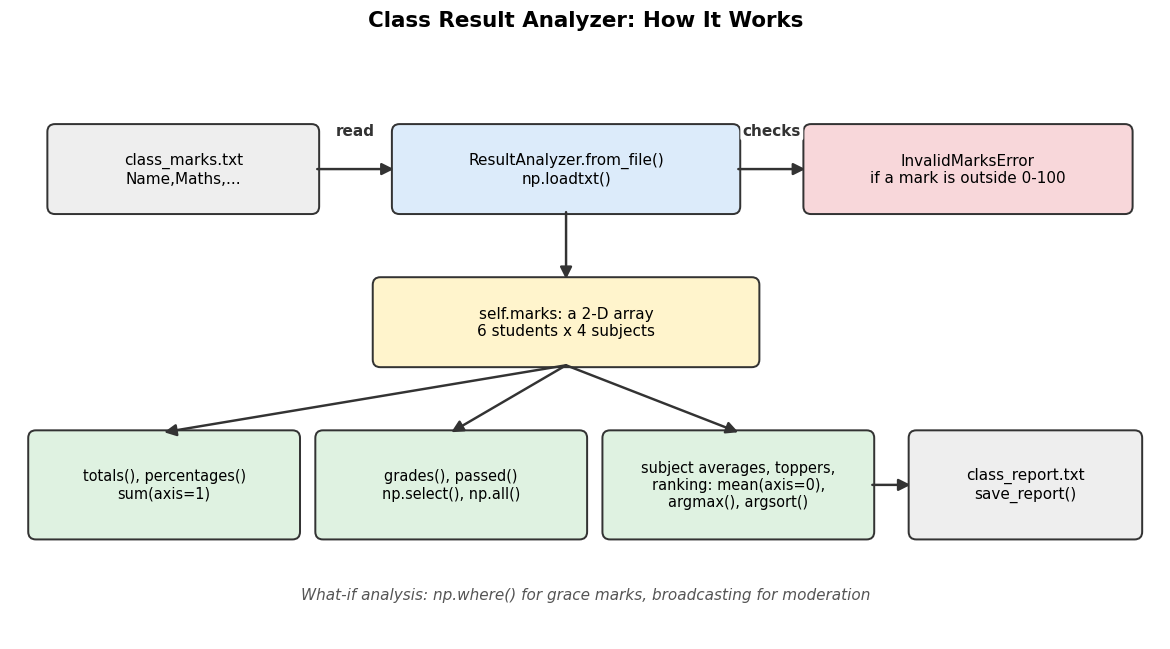

### Step 1: Create the Marks File

A header line, then one student per line: `name,maths,science,english,computer`.

In [ ]:
# Step 1: The class marks file
import numpy as np

lines = ['Name,Maths,Science,English,Computer',
         'Asha,85,92,78,95',
         'Ravi,62,55,70,68',
         'Meena,91,88,94,89',
         'John,45,38,52,60',
         'Sara,76,81,69,88',
         'Kiran,58,72,35,64']
with open('class_marks.txt', 'w', encoding='utf-8') as f:
    for line in lines:
        f.write(line + '\n')

with open('class_marks.txt', 'r', encoding='utf-8') as f:
    print(f.read(), end='')
# Expected output:
# Name,Maths,Science,English,Computer
# Asha,85,92,78,95
# Ravi,62,55,70,68
# Meena,91,88,94,89
# John,45,38,52,60
# Sara,76,81,69,88
# Kiran,58,72,35,64

### Step 2: The ResultAnalyzer Class

The class stores the names, the subjects and a 2-D array of marks (rows are students, columns are subjects). The constructor **checks** the data, and a **class method** builds an analyzer straight from a file. Every calculation is a NumPy one-liner.

In [ ]:
# Step 2: A custom exception and the ResultAnalyzer class
class InvalidMarksError(Exception):
    pass

class ResultAnalyzer:
    """Analyse a class's marks: rows are students, columns are subjects."""
    PASS_MARK = 40              # class attributes: the same rules for every class
    MAX_MARKS = 100

    def __init__(self, names, subjects, marks):
        marks = np.array(marks)
        if marks.shape != (len(names), len(subjects)):
            raise ValueError(f'marks should have shape {(len(names), len(subjects))}, got {marks.shape}')
        if np.any((marks < 0) | (marks > self.MAX_MARKS)):
            raise InvalidMarksError(f'all marks must be between 0 and {self.MAX_MARKS}')
        self.names = np.array(names)
        self.subjects = np.array(subjects)
        self.marks = marks

    @classmethod
    def from_file(cls, filename):
        """Create an analyzer from a text file: a header line, then name,mark,mark,..."""
        with open(filename, 'r', encoding='utf-8') as f:       # may raise FileNotFoundError
            header = f.readline().strip().split(',')
        names = np.loadtxt(filename, delimiter=',', skiprows=1, usecols=0, dtype=str)
        marks = np.loadtxt(filename, delimiter=',', skiprows=1, usecols=range(1, len(header)), dtype=int)
        return cls(names, header[1:], marks)

    def totals(self):
        return self.marks.sum(axis=1)                             # one total per student

    def percentages(self):
        return self.totals() * 100 / (self.marks.shape[1] * self.MAX_MARKS)

    def grades(self):
        p = self.percentages()
        return np.select([p >= 90, p >= 75, p >= 60, p >= 40], ['A+', 'A', 'B', 'C'], default='F')

    def passed(self):
        return np.all(self.marks >= self.PASS_MARK, axis=1)      # True only if every subject is passed

    def subject_averages(self):
        return self.marks.mean(axis=0)                            # one average per subject

    def subject_toppers(self):
        return self.names[self.marks.argmax(axis=0)]              # fancy indexing with argmax positions

    def ranking(self):
        return np.argsort(self.totals())[::-1]                    # positions from highest total to lowest

analyzer = ResultAnalyzer.from_file('class_marks.txt')
print(analyzer.names)
print(analyzer.subjects)
print(analyzer.marks.shape)
try:
    ResultAnalyzer(['Test'], ['Maths'], [[105]])
except InvalidMarksError as e:
    print('Rejected:', e)
# Expected output:
# ['Asha' 'Ravi' 'Meena' 'John' 'Sara' 'Kiran']
# ['Maths' 'Science' 'English' 'Computer']
# (6, 4)
# Rejected: all marks must be between 0 and 100

### Step 3: Results for Every Student

Each method returns a whole array at once: one value per student.

In [ ]:
# Step 3: Totals, percentages, grades and pass/fail
totals = analyzer.totals()
percent = analyzer.percentages()
grades = analyzer.grades()
passed = analyzer.passed()
for name, t, p, g, ok in zip(analyzer.names, totals, percent, grades, passed):
    result = 'Pass' if ok else 'Fail'
    print(f'{name:<6} total {t:>3}  {p:6.2f}%  grade {g:<2}  {result}')
print('Passed:', passed.sum(), 'of', len(passed))
print('Failed in at least one subject:', analyzer.names[~passed])
# Expected output:
# Asha   total 350   87.50%  grade A   Pass
# Ravi   total 255   63.75%  grade B   Pass
# Meena  total 362   90.50%  grade A+  Pass
# John   total 195   48.75%  grade C   Fail
# Sara   total 314   78.50%  grade A   Pass
# Kiran  total 229   57.25%  grade C   Fail
# Passed: 4 of 6
# Failed in at least one subject: ['John' 'Kiran']

### Step 4: Subject Analysis and Ranking

In [ ]:
# Step 4: Per-subject results and the class ranking
averages = analyzer.subject_averages()
toppers = analyzer.subject_toppers()
for subject, avg, top in zip(analyzer.subjects, averages, toppers):
    print(f'{subject:<9} average {avg:6.2f}   topper: {top}')
print('Hardest subject:', analyzer.subjects[averages.argmin()])
print('Ranking:', analyzer.names[analyzer.ranking()])
# Expected output:
# Maths     average  69.50   topper: Meena
# Science   average  71.00   topper: Asha
# English   average  66.33   topper: Meena
# Computer  average  77.33   topper: Asha
# Hardest subject: English
# Ranking: ['Meena' 'Asha' 'Sara' 'Ravi' 'Kiran' 'John']

### Step 5: What-if Analysis

- **Grace marks:** anyone with 35 to 39 in a subject is raised to the pass mark, using `np.where` with a combined mask.
- **Moderation:** 3 marks are added to every English mark using a broadcast row, without going above 100.

In [ ]:
# Step 5: Trying changes on copies of the data
m = analyzer.marks
graced = np.where((m >= 35) & (m < 40), 40, m)
print('Marks changed by grace:', (graced != m).sum())
after = ResultAnalyzer(analyzer.names, analyzer.subjects, graced)
print('Passed after grace marks:', after.passed().sum(), 'of', len(after.names))

moderation = np.array([0, 0, 3, 0])          # one value per subject: only English changes
moderated = m + moderation                   # broadcasting: (6, 4) + (4,)
moderated = np.where(moderated > 100, 100, moderated)
print('New English average:', round(moderated[:, 2].mean(), 2))
print('Original data unchanged:', analyzer.marks[3, 1])
# Expected output:
# Marks changed by grace: 2
# Passed after grace marks: 6 of 6
# New English average: 69.33
# Original data unchanged: 38

### Step 6: Save a Ranked Report

A normal function that writes the results to a text file in rank order (`argsort`), with aligned columns.

In [ ]:
# Step 6: Write the report file
def save_report(analyzer, filename='class_report.txt'):
    """Write a ranked result report to a text file and return its name."""
    totals = analyzer.totals()
    percent = analyzer.percentages()
    grades = analyzer.grades()
    passed = analyzer.passed()
    with open(filename, 'w', encoding='utf-8') as f:
        f.write('CLASS RESULT REPORT\n')
        f.write('=' * 44 + '\n')
        f.write('Rank Name     Total  Percent  Grade  Result\n')
        for rank, i in enumerate(analyzer.ranking(), start=1):
            result = 'Pass' if passed[i] else 'Fail'
            f.write(f'{rank:<5}{analyzer.names[i]:<8}{totals[i]:>6}{percent[i]:>9.2f}{grades[i]:>7}  {result}\n')
        f.write('-' * 44 + '\n')
        f.write(f'Class average: {percent.mean():.2f}%\n')
        f.write(f'Passed: {passed.sum()} of {len(passed)}\n')
    return filename

report = save_report(analyzer)
with open(report, 'r', encoding='utf-8') as f:
    print(f.read(), end='')
# Expected output:
# CLASS RESULT REPORT
# ============================================
# Rank Name     Total  Percent  Grade  Result
# 1    Meena      362    90.50     A+  Pass
# 2    Asha       350    87.50      A  Pass
# 3    Sara       314    78.50      A  Pass
# 4    Ravi       255    63.75      B  Pass
# 5    Kiran      229    57.25      C  Fail
# 6    John       195    48.75      C  Fail
# --------------------------------------------
# Class average: 71.04%
# Passed: 4 of 6

### Step 7: The Interactive Analyzer

The user picks a file; a wrong name is handled with `try-except-else` and the program asks again. Then a menu answers questions about the class.

In [ ]:
# Step 7: Menu-driven analyzer (uses input)
def run_analyzer():
    """Load a marks file chosen by the user, then answer questions about it."""
    while True:
        filename = input('Marks file (press Enter for class_marks.txt): ').strip()
        if filename == '':
            filename = 'class_marks.txt'
        try:
            result = ResultAnalyzer.from_file(filename)
        except FileNotFoundError:
            print(f'  {filename} was not found, try again')
        except (InvalidMarksError, ValueError) as e:
            print(f'  {filename} has bad data: {e}')
            return
        else:
            break
    while True:
        print()
        print('1. Full report  2. Find a student  3. Subject averages  4. Exit')
        choice = input('Choose an option: ').strip()
        if choice == '1':
            with open(save_report(result), 'r', encoding='utf-8') as f:
                print(f.read(), end='')
        elif choice == '2':
            name = input('Student name: ').strip().title()
            positions = np.where(result.names == name)[0]
            if len(positions) == 0:
                print(f'  No student called {name}')
                continue
            i = positions[0]
            print(f'  {name}: marks {result.marks[i]}, total {result.totals()[i]}, grade {result.grades()[i]}')
        elif choice == '3':
            for subject, avg in zip(result.subjects, result.subject_averages()):
                print(f'  {subject:<9} {avg:6.2f}')
        elif choice == '4':
            print('Goodbye!')
            break
        else:
            print('  Invalid option, choose 1 to 4')

run_analyzer()
# Example run:
# Marks file (press Enter for class_marks.txt): class10.txt
#   class10.txt was not found, try again
# Marks file (press Enter for class_marks.txt):
#
# 1. Full report  2. Find a student  3. Subject averages  4. Exit
# Choose an option: 2
# Student name: ravi
#   Ravi: marks [62 55 70 68], total 255, grade B
#
# 1. Full report  2. Find a student  3. Subject averages  4. Exit
# Choose an option: 4
# Goodbye!

### Make It Your Own

1. Add a method `above_average()` that returns the names of students above the class average
2. Add the **standard deviation** of each subject, to see which subject has the most varied marks
3. Save the percentages to a file with `np.savetxt(..., fmt='%.2f')`
4. Generate a random class of 30 students with `rng.integers(20, 101, size=(30, 4))` and analyse it
5. Add a menu option that shows everyone who failed a chosen subject

---
### Well done!

You have completed the NumPy lab. You can now create, reshape, filter and analyse arrays of numbers without writing loops. This is the foundation for pandas, Matplotlib and machine learning.